# Practical 1: Exploring and Handling Data
**Project:** Groundwater Level Prediction & Risk Classification
**Dataset:** Disclosed Ground Water Level Data under Atal Bhujal Yojana, 2015-2022 (data.gov.in, Ministry of Jal Shakti)

**Input file:** `Atal_Jal_Disclosed_Ground_Water_Level-2015-2022.csv` 
**Output file:** `01_selected_wells.csv` (used by Practical 2)

**Aim:** explore the dataset, understand its variable types, load it into suitable data structures, and select the part of the data we will use.

## Step 1: Import libraries and load the data
**What to say:** *pandas is used to hold the table and matplotlib to draw graphs. The file is not UTF-8 (common in government files), so I read it with latin-1 encoding.*

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

FILE = "Atal_Jal_Disclosed_Ground_Water_Level-2015-2022.csv"
df = pd.read_csv(FILE, encoding="latin-1")

print("Rows and columns:", df.shape)
df.head()

Rows and columns: (5490, 30)


,Sr. No.,State_Name_With_LGD_Code,District_Name_With_LGD_Code,Block_Name_With_LGD_Code,GP_Name_With_LGD_Code,Village,Site_Name,TYPE,SOURCE,Well_ID,...,Pre-monsoon_2018 (meters below ground level),Post-monsoon_2018 (meters below ground level),Pre-monsoon_2019 (meters below ground level),Post-monsoon_2019 (meters below ground level),Pre-monsoon_2020 (meters below ground level),Post-monsoon_2020 (meters below ground level),Pre-monsoon_2021 (meters below ground level),Post-monsoon_2021 (meters below ground level),Pre-monsoon_2022 (meters below ground level),Post-monsoon_2022 (meters below ground level)
0,1,Gujarat_24,Banaskantha_441,Dantiwada_3735,NaN,Deri,Deri,Piezometer,SGWD,G_1_BK_021,...,8.1,13.55,24.4,11.2,13.35,3.1,20.80,16.90,20.2,12.3
1,2,Gujarat_24,Banaskantha_441,Dantiwada_3735,Akoli_155943,Akoli,Akoli,Piezometer,SGWD,G_1_BK_018,...,15.8,21.30,55.6,49.4,57.10,34.1,58.20,49.45,51.4,46.4
2,3,Gujarat_24,Banaskantha_441,Dantiwada_3735,Bhadli Kotha_155946,Bhadli kotha,Bhadli kotha,Piezometer,SGWD,G_1_BK_019,...,27.7,21.60,27.5,21.2,20.00,19.1,19.45,18.15,Dry,Dry
3,4,Gujarat_24,Banaskantha_441,Dantiwada_3735,Dantiwada_155954,Dantiwada,Dantiwada,Piezometer,SGWD,G_1_BK_020,...,8.6,7.85,11.1,10.2,8.80,2.7,10.80,6.80,12.4,6.45
4,5,Gujarat_24,Banaskantha_441,Dantiwada_3735,Gundari_155956,Gundari,Gundari,Dug Well,SGWD,BK-105,...,15.2,11.20,17.3,13.9,16.00,10.0,22.20,19.80,21.6,20.3


## Step 2: First look at the data
**What to say:** *Each row is one groundwater monitoring well. info() shows every column, how many values are filled in, and the data type.*

In [2]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5490 entries, 0 to 5489
Data columns (total 30 columns):
 #   Column                                         Non-Null Count  Dtype  
---  ------                                         --------------  -----  
 0   Sr. No.                                        5490 non-null   int64  
 1   State_Name_With_LGD_Code                       5490 non-null   object 
 2   District_Name_With_LGD_Code                    5490 non-null   object 
 3   Block_Name_With_LGD_Code                       5473 non-null   object 
 4   GP_Name_With_LGD_Code                          4384 non-null   object 
 5   Village                                        5293 non-null   object 
 6   Site_Name                                      5245 non-null   object 
 7   TYPE                                           5490 non-null   object 
 8   SOURCE                                         5490 non-null   object 
 9   Well_ID                                        5055 

## Step 3: Understand the variable types
**What to say:** *The columns fall into four groups. Knowing the type of each variable decides how we clean it and which models we can use.*

In [3]:
reading_cols = [c for c in df.columns if "monsoon" in c]      # the 16 water level readings

variable_types = pd.DataFrame({
    "Group": ["Identifier", "Categorical (text)", "Numeric: location and size", "Numeric: water level readings"],
    "Columns": ["Sr. No., Well_ID, Site_Name",
                "State, District, Block, Village, TYPE, SOURCE, Aquifer",
                "Latitude, Longitude, Well_Depth (meters)",
                "Pre-monsoon and Post-monsoon, 2015 to 2022 (16 columns)"],
    "Use in project": ["Label each well (not used for prediction)",
                       "Describe the well and its place",
                       "Features for the models",
                       "Basis of our features and of the value we predict"]
})
variable_types

,Group,Columns,Use in project
0,Identifier,"Sr. No., Well_ID, Site_Name",Label each well (not used for prediction)
1,Categorical (text),"State, District, Block, Village, TYPE, SOURCE,...",Describe the well and its place
2,Numeric: location and size,"Latitude, Longitude, Well_Depth (meters)",Features for the models
3,Numeric: water level readings,"Pre-monsoon and Post-monsoon, 2015 to 2022 (16...",Basis of our features and of the value we predict


In [4]:
# Data type of a few important columns
print(df[["Latitude", "Longitude", "Well_Depth (meters)", "TYPE"]].dtypes)

# The 2022 readings are text, not numbers. Why?
col = "Pre-monsoon_2022 (meters below ground level)"
words = pd.to_numeric(df[col], errors="coerce").isnull() & df[col].notnull()
print()
print("Words found in", col)
print(df.loc[words, col].str.title().value_counts())

Latitude               float64
Longitude              float64
Well_Depth (meters)    float64
TYPE                    object
dtype: object

Words found in Pre-monsoon_2022 (meters below ground level)
Pre-monsoon_2022 (meters below ground level)
Dry          209
Damage        22
Filled Up     14
Collapsed      5
Abandoned      4
Closed         1
Name: count, dtype: int64


## Step 4: Summary of numeric and categorical variables
**What to say:** *For numbers I look at the average, spread, minimum and maximum. For categories I count how often each value appears.*

In [5]:
# Numeric variables
df[["Latitude", "Longitude", "Well_Depth (meters)"]].describe().round(2)

,Latitude,Longitude,Well_Depth (meters)
count,5490.00,5490.00,5490.00
mean,22.42,76.54,80.92
std,5.50,2.34,76.70
min,11.62,69.03,0.00
25%,17.71,75.55,22.11
50%,24.79,76.54,60.00
75%,26.71,77.97,112.92
max,30.45,81.51,457.31


In [6]:
# Categorical variables
print(df["TYPE"].value_counts())
print()
print(df["SOURCE"].value_counts())

TYPE
Piezometer           3378
Dug Well              891
Dug well              737
Bore Well             270
Tube Well             210
Dug Cum Bore Well       4
Name: count, dtype: int64

SOURCE
SGWD        3019
Atal Jal    1877
CGWB         594
Name: count, dtype: int64


## Step 5: Missing values
**What to say:** *Missing values must be understood before cleaning. This table shows how many values are empty in each column.*

In [7]:
missing = df.isnull().sum()
missing_table = pd.DataFrame({"missing": missing, "percent": (missing / len(df) * 100).round(1)})
missing_table[missing_table["missing"] > 0].sort_values("percent", ascending=False)

,missing,percent
Pre-monsoon_2015 (meters below ground level),2373,43.2
Pre-monsoon_2020 (meters below ground level),2345,42.7
Pre-monsoon_2016 (meters below ground level),2345,42.7
Post-monsoon_2015 (meters below ground level),2335,42.5
Pre-monsoon_2019 (meters below ground level),2316,42.2
Post-monsoon_2016 (meters below ground level),2285,41.6
Pre-monsoon_2017 (meters below ground level),2262,41.2
Pre-monsoon_2018 (meters below ground level),2246,40.9
Post-monsoon_2019 (meters below ground level),2237,40.7
Pre-monsoon_2021 (meters below ground level),2222,40.5


## Step 6: Get the state and district names
**What to say:** *State and district names have a code attached, such as Haryana_6. I split on the underscore and keep only the name.*

In [8]:
df["State"] = df["State_Name_With_LGD_Code"].str.split("_").str[0]
df["District"] = df["District_Name_With_LGD_Code"].str.split("_").str[0]

df[["State", "District"]].head()

,State,District
0,Gujarat,Banaskantha
1,Gujarat,Banaskantha
2,Gujarat,Banaskantha
3,Gujarat,Banaskantha
4,Gujarat,Banaskantha


## Step 7: Loading the data into suitable structures
**What to say:** *The same data can be held in different structures depending on the job: a DataFrame for the table, a Series for one column, a NumPy array for pure numbers, and a dictionary to keep one table per state.*

In [9]:
# 1. DataFrame: the whole table
print("DataFrame:", type(df).__name__, df.shape)

# 2. Series: one column
depth = df["Well_Depth (meters)"]
print("Series:", type(depth).__name__, len(depth))

# 3. NumPy array: numbers only (here, the coordinates of each well)
coordinates = df[["Latitude", "Longitude"]].values
print("NumPy array:", type(coordinates).__name__, coordinates.shape)

# 4. Dictionary: one DataFrame for each state
state_tables = {}
for state in df["State"].unique():
    state_tables[state] = df[df["State"] == state]

print("Dictionary of tables:", {state: len(table) for state, table in state_tables.items()})

DataFrame: DataFrame (5490, 32)
Series: Series 5490
NumPy array: ndarray (5490, 2)
Dictionary of tables: {'Gujarat': 526, 'Haryana': 622, 'Karnataka': 1250, 'Madhya Pradesh': 620, 'Maharashtra': 757, 'Rajasthan': 1021, 'Uttar Pradesh': 694}


## Step 8: Compare the states and choose which to use
**What to say:** *The dataset covers 7 states, but the amount of missing data differs a lot. I measured how many of the 16 readings are actually present for each state and chose the three most complete states. This keeps the cleaning small and the results reliable.*

                wells  districts  readings_present_%
State                                               
Gujarat           526          6                97.0
Haryana           622         14                97.0
Maharashtra       757         13                93.0
Rajasthan        1021         17                67.0
Uttar Pradesh     694         10                44.0
Karnataka        1250         14                39.0
Madhya Pradesh    620          6                34.0


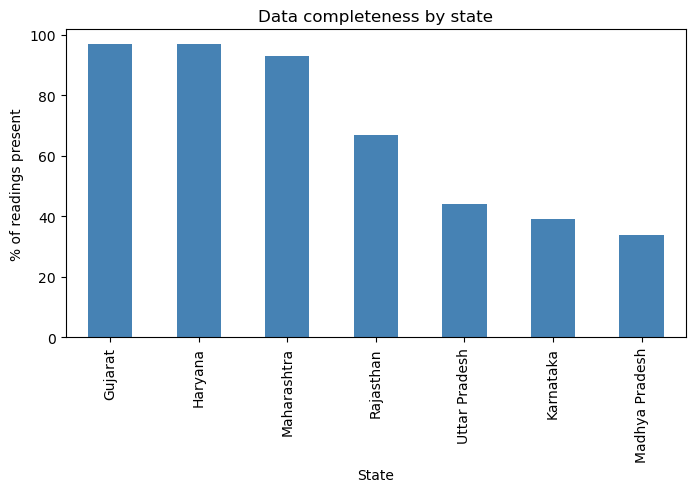

In [10]:
numeric_readings = df[reading_cols].apply(pd.to_numeric, errors="coerce")      # words become missing
completeness = numeric_readings.notna().groupby(df["State"]).mean().mean(axis=1) * 100

state_summary = pd.DataFrame({
    "wells": df.groupby("State").size(),
    "districts": df.groupby("State")["District"].nunique(),
    "readings_present_%": completeness.round(0)
}).sort_values("readings_present_%", ascending=False)

print(state_summary)

state_summary["readings_present_%"].plot(kind="bar", figsize=(8, 4), color="steelblue")
plt.ylabel("% of readings present")
plt.title("Data completeness by state")
plt.show()

In [11]:
chosen_states = ["Haryana", "Gujarat", "Maharashtra"]
df = df[df["State"].isin(chosen_states)].copy()

print("Wells in the 3 chosen states:", len(df))
print(df["State"].value_counts())

Wells in the 3 chosen states: 1905
State
Maharashtra    757
Haryana        622
Gujarat        526
Name: count, dtype: int64


## Step 9: Fix categories and remove duplicates
**What to say:** *'Dug well' and 'Dug Well' were counted as two different types, so I made the spelling the same. Wells with no ID cannot be tracked, and some wells appear twice, so I removed both.*

In [12]:
print("Well types before:", df["TYPE"].value_counts().to_dict())
df["TYPE"] = df["TYPE"].str.title()
print("Well types after: ", df["TYPE"].value_counts().to_dict())

Well types before: {'Dug well': 737, 'Piezometer': 652, 'Dug Well': 300, 'Tube Well': 210, 'Dug Cum Bore Well': 4, 'Bore Well': 2}
Well types after:  {'Dug Well': 1037, 'Piezometer': 652, 'Tube Well': 210, 'Dug Cum Bore Well': 4, 'Bore Well': 2}


In [13]:
print("Wells with no ID:", df["Well_ID"].isnull().sum())
print("Wells whose ID appears more than once:", df["Well_ID"].dropna().duplicated().sum())

df = df.dropna(subset=["Well_ID"])
df = df.drop_duplicates(subset="Well_ID")

print("Unique wells left:", len(df))

Wells with no ID: 5
Wells whose ID appears more than once: 4
Unique wells left: 1896


## Step 10: Give the reading columns shorter names
**What to say:** *The original names are very long. 'Pre-monsoon_2015 (meters below ground level)' becomes 'Pre_2015'. All values stay the same.*

In [14]:
for col in reading_cols:
    short_name = col.split(" ")[0].replace("-monsoon", "")
    df = df.rename(columns={col: short_name})

reading_cols = ["Pre_" + str(y) for y in range(2015, 2023)] + ["Post_" + str(y) for y in range(2015, 2023)]
print(reading_cols)

['Pre_2015', 'Pre_2016', 'Pre_2017', 'Pre_2018', 'Pre_2019', 'Pre_2020', 'Pre_2021', 'Pre_2022', 'Post_2015', 'Post_2016', 'Post_2017', 'Post_2018', 'Post_2019', 'Post_2020', 'Post_2021', 'Post_2022']


## Step 11: Save the selected data
**What to say:** *I kept only the columns needed for the project and saved the file. Practical 2 will start from it.*

In [15]:
columns_to_keep = ["Well_ID", "State", "District", "TYPE", "Aquifer",
                   "Latitude", "Longitude", "Well_Depth (meters)"] + reading_cols

df[columns_to_keep].to_csv("01_selected_wells.csv", index=False)

print("Saved 01_selected_wells.csv")
print("Wells:", len(df), "| Districts:", df["District"].nunique(), "| States:", df["State"].nunique())

Saved 01_selected_wells.csv
Wells: 1896 | Districts: 33 | States: 3


---
**Next: Practical 2 (Data Preprocessing)**: handling missing data, exploring numeric and categorical variables, and normalisation, starting from `01_selected_wells.csv`.